# Techcrush Data Science Class: Assignment on Exploring a Real Sales Dataset

**Name:** Okoruwa Ehinomen Mary-Cynthia

**Time:** about 1 hour

### What You Will Do
In class we explored a sales dataset from a US office supplies store, step by step. Now it is your turn to
**write the code yourself**. You will follow the same six steps from the slides:

| Step | What you do |
|:--|:--|
| 1. Load | Read the file into a DataFrame |
| 2. Inspect | Check its size, types, missing values and summary statistics |
| 3. Clean | Fix the problems you find |
| 4. Explore | Answer the store manager's questions with numbers |
| 5. Visualise | Draw charts for your answers |
| 6. Conclude | Write your findings in plain English |

### How This Assignment Works
1. **Get the data.** Download `sales_data.csv` from the class page.
   - **Google Colab:** click the folder icon on the left, then the upload icon, and upload `sales_data.csv`.
     (Files uploaded to Colab are deleted when the session ends. Upload it again if you come back later.)
   - **Jupyter or VS Code:** put `sales_data.csv` in the same folder as this notebook.
2. **Run the checker cell** below. Run it again any time you restart the notebook.
3. For each question, write your code in the cell under it, replacing every `None`.
4. Run your cell, then run the **check cell** under it.
   - `Correct` means you got it.
   - `Not yet` gives you a hint. Fix your code and run both cells again.
5. **Do not edit the check cells.**
6. Charts and written answers have no check cell. Your facilitator marks them.
7. Run the cells **in order**. Later questions use the cleaned `df` from earlier questions.

**If you get stuck:** look back at the slides and the Week 5 notebook. Every tool you need is there.

**If something breaks:** use `Runtime > Restart and run all` in Colab (or `Kernel > Restart & Run All` in Jupyter)
to run everything again from the top.

In [154]:
# Run this cell first. Do not edit it.
import hashlib

results = {}

def _norm(v, nd=None):
    if hasattr(v, "tolist"):
        v = v.tolist()
    if isinstance(v, float) and nd is not None:
        v = round(v, nd)
    if isinstance(v, (list, tuple)):
        return [_norm(x, nd) for x in v]
    if isinstance(v, str):
        v = v.strip()
    return v

def _fp(v, nd=None):
    return hashlib.md5(repr(_norm(v, nd)).encode()).hexdigest()

def check(qid, test, hint=""):
    try:
        ok = bool(test())
    except NameError as e:
        ok = False
        hint = f"{hint} (a variable is missing: {e})"
    except Exception as e:
        ok = False
        hint = f"{hint} ({type(e).__name__}: {e})"
    results[qid] = ok
    print(f"{qid}: Correct" if ok else f"{qid}: Not yet. {hint}")

print("Checker ready")

Checker ready


---
# Step 1: Load the Data

**Q1.** Import `pandas` as `pd`, `matplotlib.pyplot` as `plt` and `seaborn` as `sns`.
Then load `sales_data.csv` into a DataFrame called `df` and show the first 5 rows.

In [155]:
# YOUR CODE HERE
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("sales_data.csv")

df.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,State,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales
0,1,CA-2017-152156,08/11/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420.0,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600
1,2,CA-2017-152156,08/11/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420.0,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400
2,3,CA-2017-138688,12/06/2017,16/06/2017,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,California,90036.0,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200
3,4,US-2016-108966,11/10/2016,18/10/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311.0,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775
4,5,US-2016-108966,11/10/2016,18/10/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311.0,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680


In [156]:
# Check your answer
check('Q1', lambda: len(df) > 0, 'Check the file name, and that the file is uploaded next to the notebook.')

Q1: Correct


---
# Step 2: Inspect the Data
Look before you analyse.

**Q2.** Store the number of **rows** in `n_rows` and the number of **columns** in `n_cols`.

Hint: one attribute gives you both.

In [157]:
n_rows = df.shape[0]
n_cols = df.shape[1]

In [158]:
# Check your answer
check('Q2 rows', lambda: _fp(n_rows) == '0fbce6c74ff376d18cb352e7fdc6273b', 'Use df.shape. It gives (rows, columns).')
check('Q2 columns', lambda: _fp(n_cols) == '6f4922f45568161a8cdf4ad2299f6d23', 'The second number in df.shape.')

Q2 rows: Correct
Q2 columns: Correct


**Q3.** Run `df.info()`. Two columns hold **dates**, but Pandas stored them as text.
Write their exact names in the list `date_columns`.

In [159]:
df.info()

date_columns = ["Order Date", "Ship Date"]

<class 'pandas.DataFrame'>
RangeIndex: 9800 entries, 0 to 9799
Data columns (total 18 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         9800 non-null   int64  
 1   Order ID       9800 non-null   str    
 2   Order Date     9800 non-null   str    
 3   Ship Date      9800 non-null   str    
 4   Ship Mode      9800 non-null   str    
 5   Customer ID    9800 non-null   str    
 6   Customer Name  9800 non-null   str    
 7   Segment        9800 non-null   str    
 8   Country        9800 non-null   str    
 9   City           9800 non-null   str    
 10  State          9800 non-null   str    
 11  Postal Code    9789 non-null   float64
 12  Region         9800 non-null   str    
 13  Product ID     9800 non-null   str    
 14  Category       9800 non-null   str    
 15  Sub-Category   9800 non-null   str    
 16  Product Name   9800 non-null   str    
 17  Sales          9800 non-null   float64
dtypes: float64(2), int6

In [160]:
# Check your answer
check('Q3', lambda: sorted(date_columns) == ["Order Date", "Ship Date"], 'Look for the two columns with Date in the name. Copy the names exactly, with capital letters and spaces.')

Q3: Correct


**Q4.** Find how many values are **missing** in the whole dataset, and store the total in `total_missing`.
Then store the **name** of the only column that has missing values in `missing_column`.

Hint: `df.isna().sum()` counts per column. Add `.sum()` again for the grand total.

In [161]:
total_missing = df.isna().sum().sum()
missing_column = df.isna().sum()[df.isna().sum() > 0].index[0]

In [162]:
# Check your answer
check('Q4 total', lambda: _fp(total_missing) == '6512bd43d9caa6e02c990b0a82652dca', 'Sum the missing values over every column.')
check('Q4 column', lambda: _fp(missing_column) == '819a81ea3f9ef0e608c5d2ad22de7876', 'Which column has a number above 0 in df.isna().sum()?')

Q4 total: Correct
Q4 column: Correct


**Q5.** Store the number of **duplicate rows** in `n_duplicates`.

In [163]:
n_duplicates = df.duplicated().sum()

In [164]:
# Check your answer
check('Q5', lambda: _fp(n_duplicates) == 'cfcd208495d565ef66e7dff9f98764da', 'Use df.duplicated(), then add them up.')

Q5: Correct


**Q6.** Use `nunique()` to find how many **different** values each column has.
Store the number of different values in the `Country` column in `n_countries`.

In [165]:
n_countries = df["Country"].nunique()

In [166]:
# Check your answer
check('Q6', lambda: _fp(n_countries) == 'c4ca4238a0b923820dcc509a6f75849b', 'Use df["Country"].nunique().')

Q6: Correct


**Q7.** Find the **mean** and the **median** of the `Sales` column. Round both to 2 decimal places and store them
in `sales_mean` and `sales_median`.

Then, in the comment, explain in one sentence why the two numbers are so different.

In [167]:
sales_mean = round(df["Sales"].mean(), 2)
sales_median = round(df["Sales"].median(), 2)


# Why are they so different?
# Some sales are much higher than others; this pulls
# the average up, while the median stays closer to what a typical sale looks like.

In [168]:
# Check your answer
check('Q7 mean', lambda: _fp(sales_mean, 2) == 'b14ac110a3ad649036ec96f5654bf123', 'Use .mean() on the Sales column.')
check('Q7 median', lambda: _fp(sales_median, 2) == '53c0673ea6b9b7bd9e1daa2a80efb6ea', 'Use .median() on the Sales column.')

Q7 mean: Correct
Q7 median: Correct


---
# Step 3: Clean the Data
You found these problems in Step 2:

| Problem | Fix |
|:--|:--|
| Order Date and Ship Date are stored as text | convert them to real dates |
| Postal Code has missing values | the missing rows are all Burlington, Vermont, whose code is 05401 |
| Postal Code is stored as a decimal number | store it as 5-digit text, so 5401 becomes "05401" |
| Country has only one value, Row ID is just a counter | drop both columns |

**Remember the date trap from class:** this file writes dates **day first**. `08/11/2017` is 8 November, not 11 August.

**Q8.** Convert `Order Date` and `Ship Date` to real dates. Save each result back into the same column.

In [169]:
# YOUR CODE HERE
for col in date_columns:
    df[col] = pd.to_datetime(df[col], format="%d/%m/%Y")

In [170]:
# Check your answer
check('Q8 type', lambda: str(df["Order Date"].dtype).startswith("datetime") and str(df["Ship Date"].dtype).startswith("datetime"), 'Use pd.to_datetime() on both columns, and store the result back in the column.')
check('Q8 day first', lambda: df["Order Date"].iloc[0].month == 11, 'The first order should be in November. Did you add dayfirst=True?')

Q8 type: Correct
Q8 day first: Correct


**Q9.** Fill the missing postal codes with `5401`, then turn the whole `Postal Code` column into 5-digit text.

Hint: `.astype(int).astype(str).str.zfill(5)` adds zeros at the front until the text is 5 characters long.

In [171]:
# YOUR CODE HERE
df["Postal Code"] = df["Postal Code"].fillna(5401)

df["Postal Code"] = df["Postal Code"].astype(int).astype(str).str.zfill(5)

In [172]:
# Check your answer
check('Q9 missing', lambda: df["Postal Code"].isna().sum() == 0, 'Use fillna(5401) on Postal Code.')
check('Q9 text', lambda: df.loc[(df["City"] == "Burlington") & (df["State"] == "Vermont"), "Postal Code"].iloc[0] == "05401", 'Turn the column into text with 5 characters, using zfill(5).')

Q9 missing: Correct
Q9 text: Correct


**Q10.** Drop the `Country` and `Row ID` columns. Save the result back into `df`.

If you see a `KeyError`, you have probably already dropped them. Re-run the notebook from the top.

In [173]:
# YOUR CODE HERE
df = df.drop(columns=["Country", "Row ID"])

In [174]:
# Check your answer
check('Q10', lambda: "Country" not in df.columns and "Row ID" not in df.columns, 'Use df.drop(columns=[...]) and save the result back into df.')

Q10: Correct


**Q11.** Add three new columns:
- `Order Year`: the year of the order date
- `Order Month`: the month of the order date, as a number from 1 to 12
- `Days to Ship`: the number of days between the order date and the ship date

Hint: `.dt.year`, `.dt.month`, and `.dt.days` after subtracting two date columns.

In [175]:
# YOUR CODE HERE
df["Order Year"] = df["Order Date"].dt.year
df["Order Month"] = df["Order Date"].dt.month

df["Days to Ship"] = (df["Ship Date"] - df["Order Date"]).dt.days

In [176]:
# Check your answer
check('Q11 year', lambda: _fp(df["Order Year"].sum()) == '36e744fc8fb8c1c047f63e10d46b3307', 'Use .dt.year on Order Date.')
check('Q11 month', lambda: _fp(df["Order Month"].sum()) == '14cbd7ab31dba4f0b37818b4286d7549', 'Use .dt.month on Order Date. Check that the dates were read day first.')
check('Q11 days', lambda: _fp(df["Days to Ship"].sum()) == 'effa6c4644b3dcb6a4ab6159e328f99e', 'Subtract Order Date from Ship Date, then use .dt.days.')

Q11 year: Correct
Q11 month: Correct
Q11 days: Correct


---
# Step 4: Explore the Data
Now answer the store manager's questions. Use the cleaned `df`.

**Q12. How big is the business?**
- `total_sales`: the total of the `Sales` column, rounded to 2 decimal places
- `n_orders`: the number of **orders** (careful: one order can take up several rows)
- `n_customers`: the number of different customers

In [177]:
total_sales = round(df["Sales"].sum(), 2)
n_orders = df["Order ID"].nunique()
n_customers = df["Customer ID"].nunique()


In [178]:
# Check your answer
check('Q12 sales', lambda: _fp(total_sales, 2) == '0365241b320d723ecfae7c11cd42c207', 'Sum the Sales column.')
check('Q12 orders', lambda: _fp(n_orders) == '79e785d63f00348ff360d5a86528580b', 'Count the unique Order IDs, not the rows.')
check('Q12 customers', lambda: _fp(n_customers) == 'da8ce53cf0240070ce6c69c48cd588ee', 'Count the unique Customer IDs.')

Q12 sales: Correct
Q12 orders: Correct
Q12 customers: Correct


**Q13. Which category sells most?**
Create `sales_by_category`: the total sales for each `Category`, sorted from highest to lowest.
Print it, then store the **name** of the top category in `top_category`.

In [179]:
sales_by_category = df.groupby("Category")["Sales"].sum().sort_values(ascending=False)
print(sales_by_category)

top_category = sales_by_category.index[0]

Category
Technology         827455.8730
Furniture          728658.5757
Office Supplies    705422.3340
Name: Sales, dtype: float64


In [180]:
# Check your answer
check('Q13', lambda: _fp(top_category) == 'db31d2501acb15174134e8f3ffc47e91', 'Group by Category, sum Sales, sort from highest. The top name is the first index value.')

Q13: Correct


**Q14. Which sub-categories sell most?**
Store the names of the **top 3** sub-categories by total sales, highest first, in the list `top_3_subcats`.

Hint: group, sum, sort, `.head(3)`, then `.index.tolist()`.

In [181]:
top_3_subcats = df.groupby("Sub-Category")["Sales"].sum().sort_values(ascending=False).head(3).index.tolist()

In [182]:
# Check your answer
check('Q14', lambda: _fp(top_3_subcats) == '66ab64ba2bbc46f72a0ff2af14beb877', 'Make sure it is a list of 3 names, highest first.')

Q14: Correct


**Q15. Which regions sell most and least?**
Store the name of the region with the **highest** total sales in `best_region`, and the **lowest** in `worst_region`.

Hint: `.idxmax()` and `.idxmin()` give the label of the largest and smallest value.

In [183]:
sales_by_region = df.groupby("Region")["Sales"].sum()

best_region = sales_by_region.idxmax()
worst_region = sales_by_region.idxmin()

In [184]:
# Check your answer
check('Q15 best', lambda: _fp(best_region) == '0e4e20a9da538af1a558a6e194a9e315', 'Group by Region and sum Sales first.')
check('Q15 worst', lambda: _fp(worst_region) == '8f897464b377ff702b751ed8019b568a', 'Use .idxmin() for the lowest.')

Q15 best: Correct
Q15 worst: Correct


**Q16. Are sales growing?**
1. Create `sales_by_year`: total sales for each `Order Year`. Print it.
2. Store the percentage growth from **2015** to **2018** in `growth_pct`, rounded to 1 decimal place.

Growth formula: `(sales in 2018 - sales in 2015) / sales in 2015 * 100`

In [185]:

sales_by_year = df.groupby("Order Year")["Sales"].sum()
print(sales_by_year)

growth_pct = round(
    (sales_by_year.loc[2018] - sales_by_year.loc[2015])
    / sales_by_year.loc[2015] * 100, 1
)

Order Year
2015    479856.2081
2016    459436.0054
2017    600192.5500
2018    722052.0192
Name: Sales, dtype: float64


In [186]:
# Check your answer
check('Q16', lambda: _fp(growth_pct, 1) == 'd04ccdb03137646ee43d0dc741ee3d80', 'Use sales_by_year[2018] and sales_by_year[2015]. Did you convert the dates day first?')

Q16: Correct


**Q17. Which month is busiest?**
Using `Order Month`, find the month number (1 to 12) with the **highest** total sales across all four years.
Store it in `busiest_month`.

In [187]:
sales_by_month = df.groupby("Order Month")["Sales"].sum()

busiest_month = sales_by_month.idxmax()

In [188]:
# Check your answer
check('Q17', lambda: _fp(busiest_month) == '6512bd43d9caa6e02c990b0a82652dca', 'Group by Order Month, sum Sales, then .idxmax().')

Q17: Correct


**Q18. How long does shipping take?**
Find the **average** `Days to Ship` for each `Ship Mode`. Print it.
Store the average for **Standard Class**, rounded to 1 decimal place, in `standard_days`.

In [189]:

avg_shipping_days = df.groupby("Ship Mode")["Days to Ship"].mean()
print(avg_shipping_days)

standard_days = round(avg_shipping_days.loc["Standard Class"], 1)

Ship Mode
First Class       2.179214
Same Day          0.044610
Second Class      3.249211
Standard Class    5.008363
Name: Days to Ship, dtype: float64


In [190]:
# Check your answer
check('Q18', lambda: _fp(standard_days, 1) == '336669dbe720233ed5577ddf81b653d3', 'Group by Ship Mode, take the mean of Days to Ship, then pick Standard Class.')

Q18: Correct


**Q19. Who is the best customer?**
Store the **name** of the customer with the highest total sales in `top_customer`.

In [191]:
sales_by_customer = df.groupby("Customer Name")["Sales"].sum()

top_customer = sales_by_customer.idxmax()

In [192]:
# Check your answer
check('Q19', lambda: _fp(top_customer) == '007517e88f915d2dc79b743824635fd6', 'Group by Customer Name and sum Sales.')

Q19: Correct


**Q20. Are there unusually large sales?**
Store the number of rows where `Sales` is **more than 5000** in `big_sales`.
Then print the `Product Name`, `Customer Name` and `Sales` of the **single largest** sale.

In [193]:
big_sales = (df["Sales"] > 5000).sum()

largest_sale = df.loc[df["Sales"].idxmax(), ["Product Name", "Customer Name", "Sales"]]

# Print the single largest sale here
print(largest_sale)

Product Name     Cisco TelePresence System EX90 Videoconferenci...
Customer Name                                          Sean Miller
Sales                                                     22638.48
Name: 2697, dtype: object


In [194]:
# Check your answer
check('Q20', lambda: _fp(big_sales) == '1f0e3dad99908345f7439f8ffabdffc4', 'Filter rows with Sales > 5000 and count them. (df["Sales"] > 5000).sum() works too.')

Q20: Correct


---
# Step 5: Visualise
There are no check cells here. Your facilitator marks your charts.

**Every chart must have a title and labelled axes.** Sort bars from highest to lowest where it helps.

**Q21.** Draw a **bar chart** of total sales by **Category**.

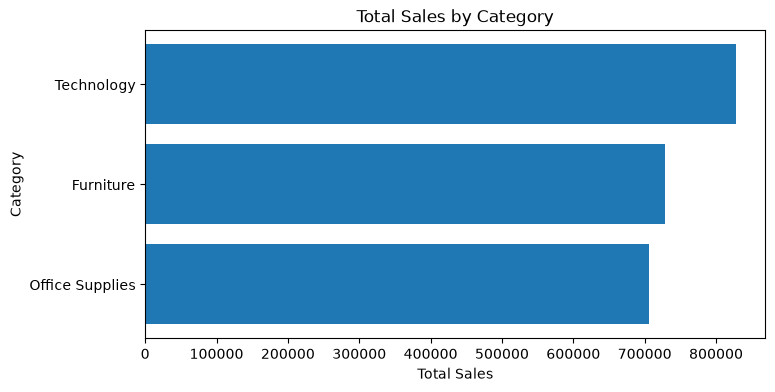

In [195]:
# YOUR CODE HERE

plt.figure(figsize=(8, 4))
plt.barh(sales_by_category.sort_values(ascending=False).index,
         sales_by_category.sort_values(ascending=False).values)
plt.title("Total Sales by Category")
plt.xlabel("Total Sales")
plt.ylabel("Category")
plt.gca().invert_yaxis()
plt.show()

**Q22.** Draw a **horizontal bar chart** of total sales for all 17 **sub-categories**, sorted so the biggest is at the top.

Hint: sort from lowest to highest, then use `plt.barh()`. The last bar is drawn at the top.

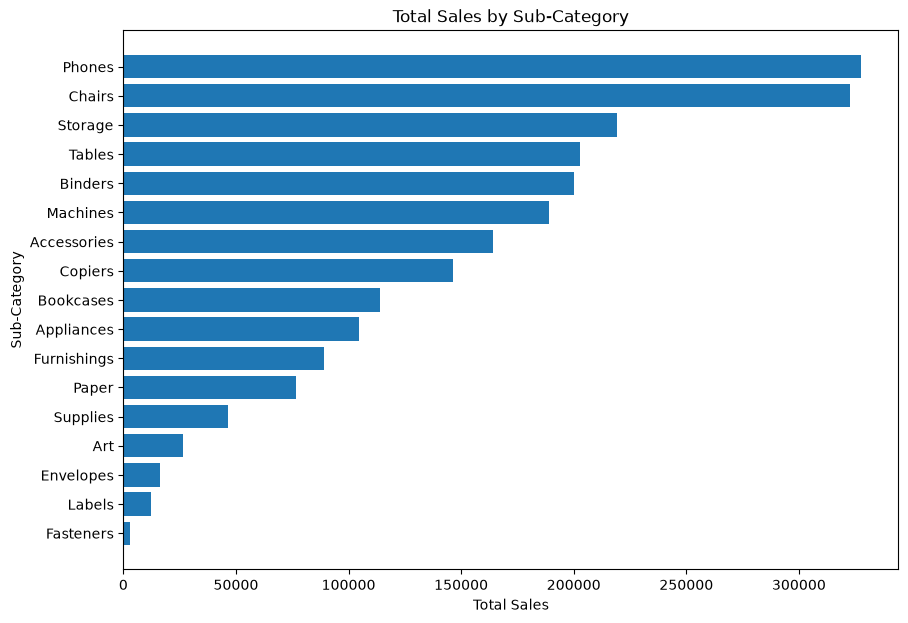

In [196]:
# YOUR CODE HERE
sales_by_subcategory = df.groupby("Sub-Category")["Sales"].sum()

sorted_sales = sales_by_subcategory.sort_values(ascending=True)

plt.figure(figsize=(10, 7))
plt.barh(sorted_sales.index, sorted_sales.values)

plt.title("Total Sales by Sub-Category")
plt.xlabel("Total Sales")
plt.ylabel("Sub-Category")

plt.show()

**Q23.** Draw a **line chart** of total sales for each **Order Month** (1 to 12), across all four years.
Add markers to the line so each month shows as a point.

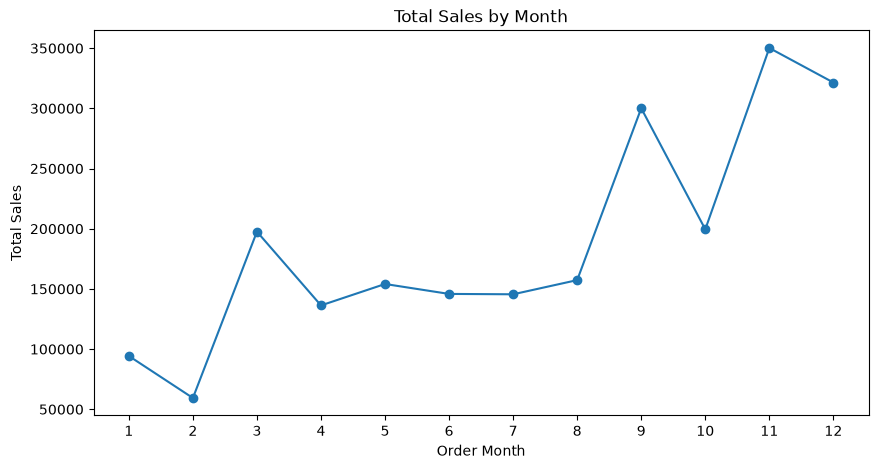

In [197]:
# YOUR CODE HERE
sales_by_month = df.groupby("Order Month")["Sales"].sum().sort_index()

plt.figure(figsize=(10, 5))
plt.plot(sales_by_month.index, sales_by_month.values, marker="o")

plt.title("Total Sales by Month")
plt.xlabel("Order Month")
plt.ylabel("Total Sales")
plt.xticks(range(1, 13))

plt.show()

**Q24.** Draw a **histogram** of `Sales` for rows where `Sales` is **1000 or less**, with 30 bins.

Why only up to 1000? Try it with every row first. A few huge sales squash all the other bars into one,
which is the same reason the mean and median were so far apart.

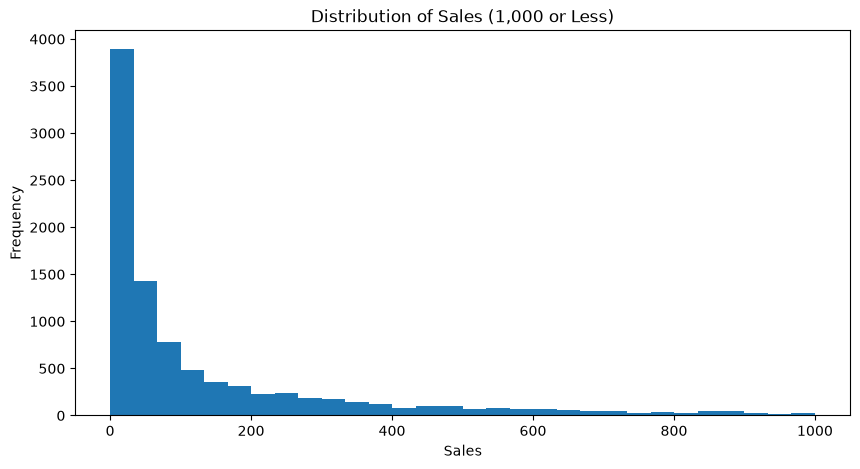

In [198]:
# YOUR CODE HERE
plt.figure(figsize=(10, 5))
plt.hist(df[df["Sales"] <= 1000]["Sales"], bins=30)

plt.title("Distribution of Sales (1,000 or Less)")
plt.xlabel("Sales")
plt.ylabel("Frequency")

plt.show()

**Q25 (bonus).** Use `pd.crosstab()` to make a table of total sales with **Region** as rows and **Category** as columns.
Then draw it with `sns.heatmap()`. Use `annot=True, fmt=".0f"` to show the numbers.

Category    Furniture  Office Supplies  Technology
Region                                            
Central   160317.4622       163590.243  168739.208
East      206461.3880       199940.811  263116.527
South     116531.4800       124424.771  148195.208
West      245348.2455       217466.509  247404.930


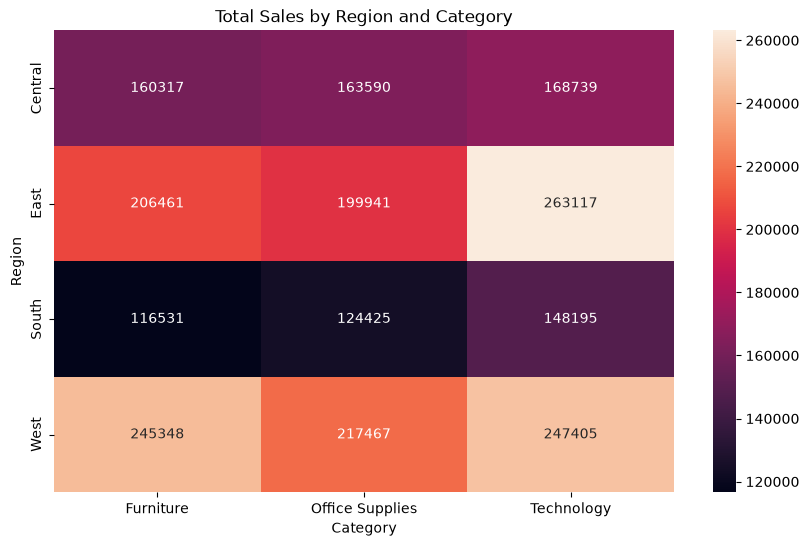

In [199]:
# YOUR CODE HERE
sales_region_category = pd.crosstab(
    df["Region"],
    df["Category"],
    values=df["Sales"],
    aggfunc="sum"
)

print(sales_region_category)

plt.figure(figsize=(10, 6))
sns.heatmap(sales_region_category, annot=True, fmt=".0f")

plt.title("Total Sales by Region and Category")
plt.xlabel("Category")
plt.ylabel("Region")

plt.show()

---
# Step 6: Conclude

**Q26.** Double click this cell and write **three findings** for the store manager.

A good finding is **one sentence with a number in it** that someone could act on.

- Weak: *"Not many people use Same Day shipping."*
- Strong: *"Only 5.5% of order lines use Same Day shipping."*

**Your findings:**

1. Sales grew 50.5% from 2015 to 2018, rising from $479,856.21 to $722,052.02, so the business is growing overall.

2. The West region sells the most ($710,219.68, 31.4% of sales), which is about 1.8 times the South region’s $389,151.46 (17.2%).

3. In the East region, Technology brings in $263,116.53, which is 39.3% of that region’s sales and the highest single Region and Category figure in the table.

**One action** you would suggest to the manager, based on your findings:

- The South has the lowest sales, and its Technology sales of $148,195.21 are well below the East’s $263,116.53, so the manager should run regional promotions and improve Technology stock in the South to close the gap.



---
# Your Score
Run the cell below to see how many checks you have passed. Charts and written answers are marked separately.

In [200]:
TOTAL_CHECKS = 30

passed_ids = [k for k, v in results.items() if v]
failed_ids = [k for k, v in results.items() if not v]

print(f"Checks passed: {len(passed_ids)} of {TOTAL_CHECKS}")
print(f"Checks not run yet: {TOTAL_CHECKS - len(results)}")
if failed_ids:
    print("Still to fix:", ", ".join(failed_ids))
elif len(results) == TOTAL_CHECKS:
    print("Every check passes. Well done.")

Checks passed: 30 of 30
Checks not run yet: 0
Every check passes. Well done.


---
# How to Submit

Before you submit, check that:
- [ ] Your name is at the top of the notebook
- [ ] Every code cell has been run, so the outputs and charts are showing
- [ ] Your score cell above has been run
- [ ] Your three findings and your action are written in Q26

**Then submit in one of two ways:**

- **Upload the notebook:** in Colab, `File > Download > Download .ipynb`, then upload that file.
- **Share a Colab link:** click `Share` at the top right, set access to **Anyone with the link**, copy the link and submit it.
  If the link is not set to "Anyone with the link", it cannot be opened or marked.

**Do not upload `sales_data.csv`.** Only your notebook.